### Data

Daily FX spot rates from FRED (Federal Reserve **H.10** release, noon buying rates in New York), downloaded directly in the next cell. No API key is needed.

| Currency | FRED series | FRED quote | Processing |
|---|---|---|---|
| AUD | [`DEXUSAL`](https://fred.stlouisfed.org/series/DEXUSAL) | USD per AUD | none |
| EUR | [`DEXUSEU`](https://fred.stlouisfed.org/series/DEXUSEU) | USD per EUR | none |
| JPY | [`DEXJPUS`](https://fred.stlouisfed.org/series/DEXJPUS) | JPY per USD | inverted |
| CHF | [`DEXSZUS`](https://fred.stlouisfed.org/series/DEXSZUS) | CHF per USD | inverted |
| GBP | [`DEXUSUK`](https://fred.stlouisfed.org/series/DEXUSUK) | USD per GBP | none |

Processing steps:
1. **Same quote direction.** JPY and CHF are inverted so that every series is USD per 1 unit of the foreign currency. A positive return then always means the foreign currency strengthened against the dollar, which makes skew and the GJR leverage term comparable across pairs. For log returns, inverting only flips the sign, so variances and all volatility forecasts are unaffected.
2. **Common calendar.** FRED leaves US holidays blank. Dates where any pair is missing are dropped, so every pair shares the same dates.
3. **Returns.** Daily log returns in percent: `100 * ln(P_t / P_{t-1})`.

The sample is fixed at `START`–`END` so results are reproducible. FRED keeps adding new days, so move `END` forward on purpose when you want fresher data.


### Import Libraries and Modules

In [1]:
%reload_ext autoreload
%autoreload 2

import numpy as np
from arch import arch_model

from src.benchmarks import hist_var, ewma
from src.data import fetch_returns

from src.garch import param_table, summary_table
from src.pipeline import get_forecasts

### Fetch FX Returns

In [2]:
returns = fetch_returns()

### Perform EDA 

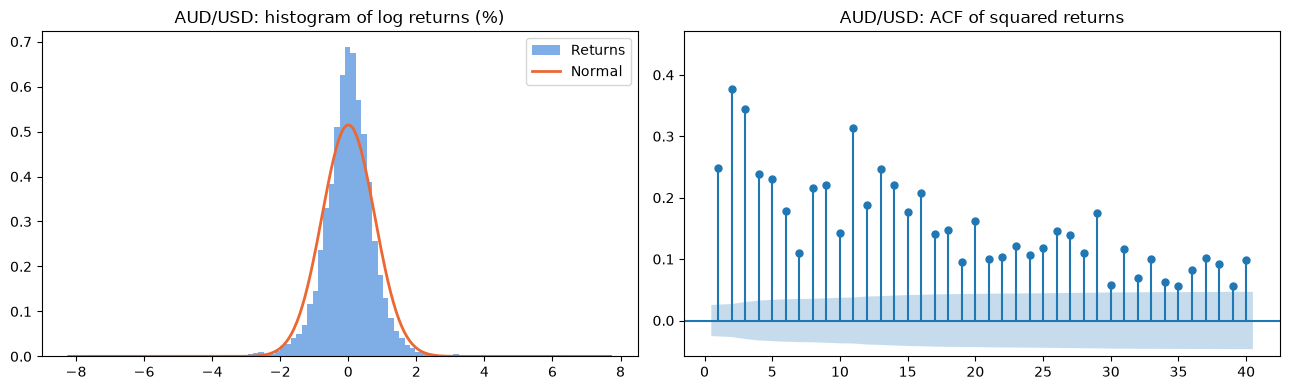

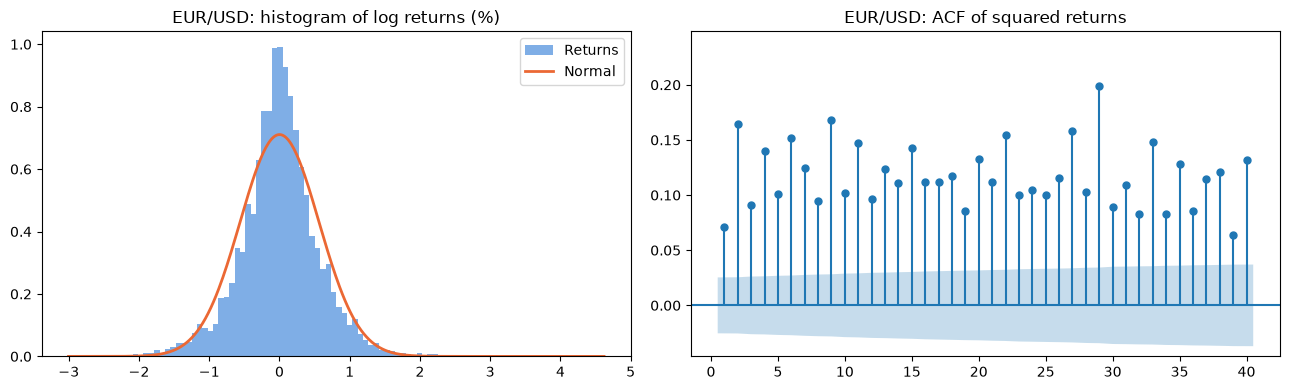

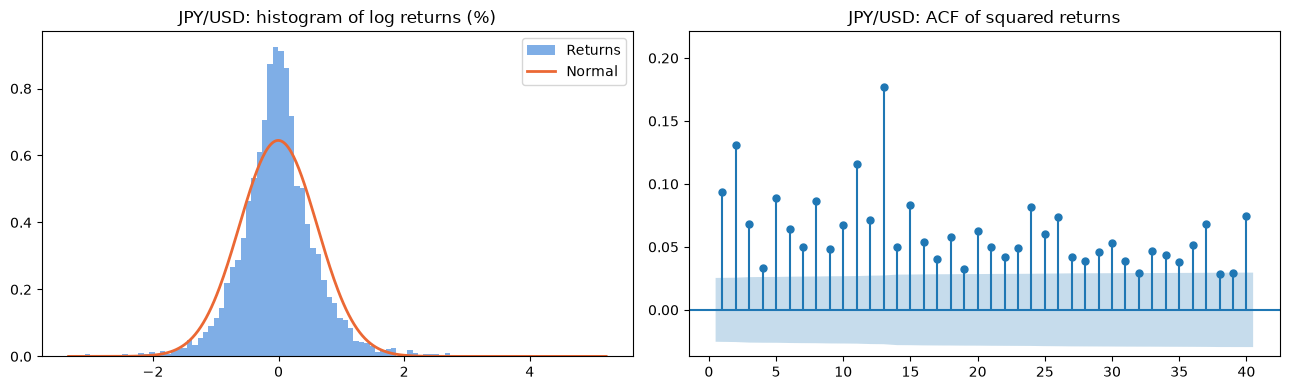

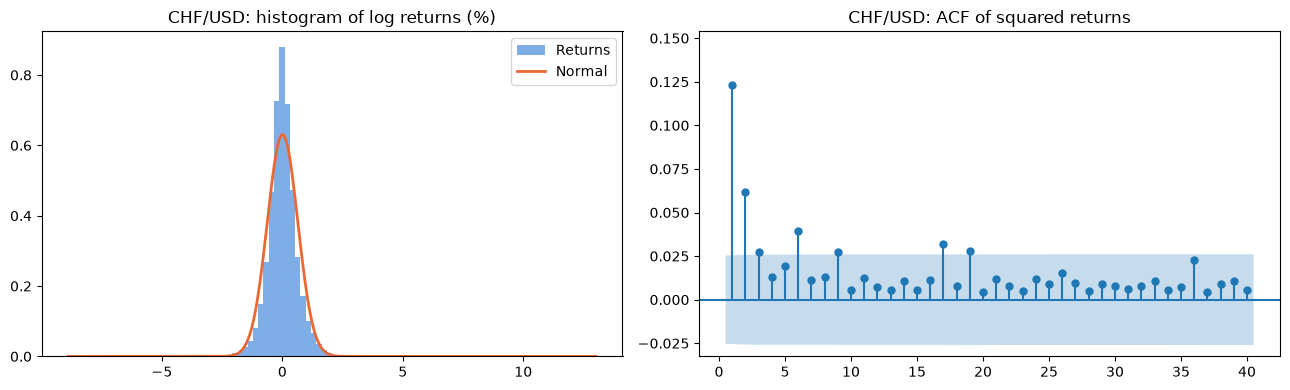

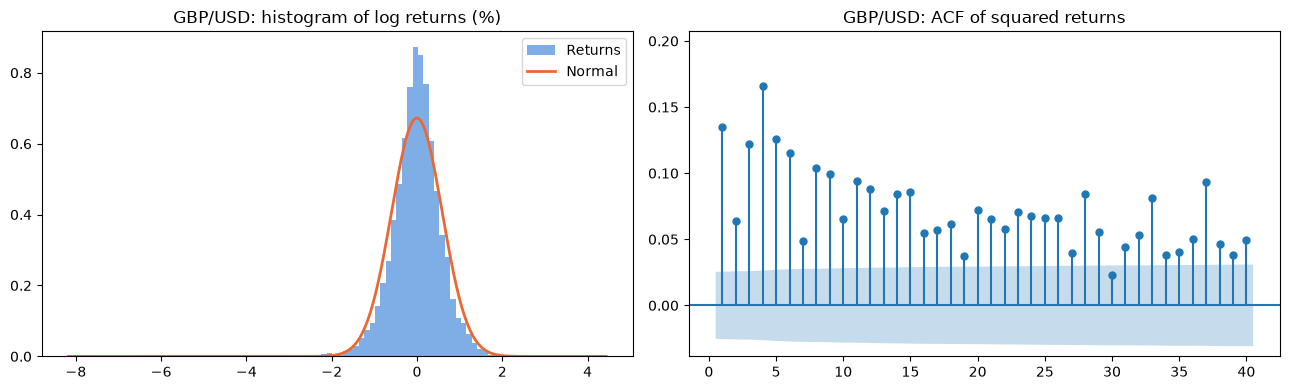

Summary stats


,AUD,EUR,JPY,CHF,GBP
n,5978.0000,5978.0000,5978.0000,5978.0000,5978.0000
mean,0.0033,0.0012,-0.0046,0.0090,-0.0030
std,0.7750,0.5614,0.6185,0.6326,0.5933
ann_vol_%,12.3030,8.9120,9.8187,10.0419,9.4190
min,-8.2120,-3.0031,-3.3428,-8.8907,-8.1694
max,7.7035,4.6208,5.2156,13.0222,4.4349
skew,-0.6128,0.1057,0.4046,1.2463,-0.6207
excess_kurt,11.9588,2.9220,4.6773,39.1914,10.2441
JB_stat,35996.3704,2137.7934,5612.2461,384130.4888,26522.8879
JB_p,0.0000,0.0000,0.0000,0.0000,0.0000


Test p-values


,AUD,EUR,JPY,CHF,GBP
LB returns Q(10),0.0,0.1524,0.4265,0.0264,0.0
LB squared Q(10),0.0,0.0000,0.0000,0.0000,0.0
LB returns Q(20),0.0,0.3334,0.0913,0.0001,0.0
LB squared Q(20),0.0,0.0000,0.0000,0.0000,0.0
ARCH LM (10 lags),0.0,0.0000,0.0000,0.0000,0.0


In [3]:
from src.eda import plot_eda, summary_stats, dependence_tests

# EDA for all five pairs
for c in returns.columns:
  plot_eda(returns[c], f"{c}/USD")

print("Summary stats")
display(returns.apply(summary_stats).round(4))

print("Test p-values")
display(returns.apply(lambda r: dependence_tests(r)["p_value"]).round(4))

### Run Benchmarks and GARCH Estimation on EUR/USD

In [4]:
# Run benchmarks on EUR/USD
benchmark_forecasts = get_forecasts(
  returns=returns["EUR"],
  models={
  "hist_30": hist_var(30),
  "hist_60": hist_var(60),
  "hist_250": hist_var(250),
  "ewma": ewma(0.94)
})
benchmark_forecasts.tail()

,realized,hist_30,hist_60,hist_250,ewma
observation_date,,,,,
2026-11-02,0.366612,0.118298,0.091665,0.117951,0.098014
2026-11-03,-0.107162,0.125251,0.094114,0.118391,0.100198
2026-11-04,0.223125,0.124760,0.091729,0.118405,0.094875
2026-11-05,0.160342,0.125603,0.093005,0.118169,0.092170
2026-11-06,-0.723573,0.124540,0.093718,0.118277,0.088182


In [5]:
# In-sample GARCH estimation: GARCH(1,1) and GJR-GARCH on the full EUR/USD sample
fits = {
  "GARCH(1,1)": arch_model(returns["EUR"], mean="Constant", vol="GARCH", p=1, q=1, dist="normal").fit(disp="off"),
  "GJR-GARCH(1,1,1)": arch_model(returns["EUR"], mean="Constant", vol="GARCH", p=1, o=1, q=1, dist="normal").fit(disp="off"),
}

for name, res in fits.items():
  print(name)
  display(param_table(res).round(4))

display(summary_table(fits))

GARCH(1,1)


,coef,std_err,t_stat,p_value
mu,0.0008,0.0061,0.1351,0.8925
omega,0.0012,0.0005,2.4279,0.0152
alpha[1],0.0337,0.0041,8.3163,0.0000
beta[1],0.9625,0.0047,206.5452,0.0000


GJR-GARCH(1,1,1)


,coef,std_err,t_stat,p_value
mu,-0.0016,0.0061,-0.2590,0.7957
omega,0.0010,0.0005,2.3152,0.0206
alpha[1],0.0238,0.0057,4.2000,0.0000
gamma[1],0.0153,0.0061,2.4979,0.0125
beta[1],0.9653,0.0047,203.8196,0.0000


,persistence,half-life (days),long-run vol (% a year),AIC,BIC
"GARCH(1,1)",0.9962,180.7,8.88,9018.3,9045.1
"GJR-GARCH(1,1,1)",0.9967,208.3,8.92,9011.5,9045.0


**Leverage effect:** in the GJR model, γ = 0.015 (t = 2.50, p = 0.013), so it's significant at 5%. Euro sell-offs raise EUR/USD volatility slightly more than rallies of the same size. The effect is small, though: AIC prefers GJR, but BIC, which penalises the extra parameter, rates the two models about equal.

### Evaluate Forecasts

In [6]:
from src.evaluation import score

# Score the benchmarks on EUR/USD: MAE, RMSE and QLIKE against squared returns (lower is better)
score(benchmark_forecasts).round(4)

,MAE,RMSE,QLIKE
hist_30,0.3291,0.6726,-0.3199
hist_60,0.3304,0.6743,-0.3247
hist_250,0.3420,0.6935,-0.2576
ewma,0.3288,0.6727,-0.3279


### VaR Backtests

In [7]:
from src.risk import backtest

# 99% and 95% VaR backtests for the benchmarks on EUR/USD (p < 0.05 = model rejected)
backtest(benchmark_forecasts).round(4)

hits  hit_rate    p_uc   p_ind    p_cc  avg_VaR  avg_ES
model    alpha                                                         
hist_30  0.01    101    0.0176  0.0000  0.5168  0.0000   1.2145  1.3914
         0.05    341    0.0595  0.0013  0.3870  0.0039   0.8587  1.0768
hist_60  0.01     96    0.0168  0.0000  0.7519  0.0000   1.2258  1.4044
         0.05    319    0.0557  0.0521  0.0086  0.0048   0.8667  1.0869
hist_250 0.01    106    0.0185  0.0000  0.0174  0.0000   1.2596  1.4430
         0.05    302    0.0527  0.3483  0.0001  0.0002   0.8906  1.1168
ewma     0.01    100    0.0175  0.0000  0.0607  0.0000   1.2182  1.3957
         0.05    328    0.0573  0.0136  0.8575  0.0469   0.8614  1.0802

### Calm vs Stressed Regimes

In [8]:
from src.regimes import regime_labels

# Day t is "stressed" when the past 20 days' volatility is in the top quarter of everything seen so far
regimes = returns.apply(regime_labels)

# Share of calm vs stressed days per pair
regimes.apply(lambda s: s.value_counts(normalize=True)).round(3)

,AUD,EUR,JPY,CHF,GBP
calm,0.804,0.813,0.744,0.861,0.78
stressed,0.196,0.187,0.256,0.139,0.22


### Run All Models on All Pairs

In [9]:
from src.pipeline import run_all

# Every model on every pair: forecasts, scores, VaR backtests, calm/stressed scores (~1.5 min)
run = run_all(returns)

AUD/USD: 5728 forecast days, 19s, GARCH fits (total, failed, odd): {'garch11': (287, 0, 2), 'gjr_garch': (287, 0, 20)}


EUR/USD: 5728 forecast days, 20s, GARCH fits (total, failed, odd): {'garch11': (287, 0, 31), 'gjr_garch': (287, 0, 36)}


JPY/USD: 5728 forecast days, 19s, GARCH fits (total, failed, odd): {'garch11': (287, 0, 0), 'gjr_garch': (287, 0, 28)}


CHF/USD: 5728 forecast days, 19s, GARCH fits (total, failed, odd): {'garch11': (287, 0, 101), 'gjr_garch': (287, 0, 153)}


GBP/USD: 5728 forecast days, 19s, GARCH fits (total, failed, odd): {'garch11': (287, 0, 0), 'gjr_garch': (287, 0, 0)}


### Results

In [10]:
import pandas as pd

print("Forecast accuracy (lower is better)")
display(run["results"].round(4))

print("Best model per pair")
display(pd.DataFrame({k: run["results"][k].unstack("model").idxmin(axis=1) for k in ["MAE", "RMSE", "QLIKE"]}))

print("Diebold-Mariano: GJR-GARCH vs each model on QLIKE (DM_stat < 0 = GJR better, p < 0.05 = significant)")
display(run["dm"].round(4))

print("Diebold-Mariano in calm vs stressed periods")
display(run["dm_by_regime"].round(4))

print("VaR backtests (p < 0.05 = model rejected)")
display(run["risk"].round(4))

print("Accuracy in calm vs stressed periods")
display(run["by_regime"].round(4))

print("Next-day volatility forecast, annualised %")
display(run["next_day_vol"].round(2))

Forecast accuracy (lower is better)


MAE    RMSE   QLIKE
currency model                            
AUD      hist_30    0.6457  2.1480  0.2255
         hist_60    0.6542  2.2082  0.2429
         hist_250   0.6826  2.2570  0.3445
         ewma       0.6397  2.0875  0.2139
         garch11    0.6435  2.1041  0.2095
         gjr_garch  0.6405  2.0979  0.2105
EUR      hist_30    0.3291  0.6726 -0.3199
         hist_60    0.3304  0.6743 -0.3247
         hist_250   0.3420  0.6935 -0.2576
         ewma       0.3288  0.6727 -0.3279
         garch11    0.3355  0.6718 -0.3420
         gjr_garch  0.3354  0.6715 -0.3423
JPY      hist_30    0.4283  0.9905 -0.0359
         hist_60    0.4286  0.9887 -0.0414
         hist_250   0.4367  0.9963 -0.0060
         ewma       0.4238  0.9837 -0.0670
         garch11    0.4256  0.9823 -0.0832
         gjr_garch  0.4244  0.9821 -0.0830
CHF      hist_30    0.4596  2.6516 -0.0670
         hist_60    0.4568  2.6327 -0.0482
         hist_250   0.4584  2.6228  0.0623
         ewma       0.4502  2.6308 -0.0601
         garch11    0.4676  2.6253 -0.0746
         gjr_garch  0.4516  2.6097 -0.0669
GBP      hist_30    0.3827  1.2348 -0.2031
         hist_60    0.3830  1.2306 -0.2028
         hist_250   0.3927  1.2505 -0.1155
         ewma       0.3775  1.2208 -0.2248
         garch11    0.3810  1.2239 -0.2312
         gjr_garch  0.3808  1.2260 -0.2277

Best model per pair


,MAE,RMSE,QLIKE
currency,,,
AUD,ewma,ewma,garch11
EUR,ewma,gjr_garch,gjr_garch
JPY,ewma,gjr_garch,garch11
CHF,ewma,gjr_garch,garch11
GBP,ewma,ewma,garch11


Diebold-Mariano: GJR-GARCH vs each model on QLIKE (DM_stat < 0 = GJR better, p < 0.05 = significant)


DM_stat  p_value
currency model                     
AUD      hist_30   -2.2423   0.0249
         hist_60   -2.7715   0.0056
         hist_250  -3.8778   0.0001
         ewma      -0.5820   0.5605
         garch11    0.4252   0.6707
EUR      hist_30   -2.6674   0.0076
         hist_60   -3.1113   0.0019
         hist_250  -5.8759   0.0000
         ewma      -2.1186   0.0341
         garch11   -0.2322   0.8164
JPY      hist_30   -3.2658   0.0011
         hist_60   -3.1907   0.0014
         hist_250  -4.2093   0.0000
         ewma      -1.5729   0.1158
         garch11    0.0762   0.9392
CHF      hist_30    0.0030   0.9976
         hist_60   -1.8058   0.0709
         hist_250  -1.7644   0.0777
         ewma      -0.7691   0.4418
         garch11    0.8789   0.3794
GBP      hist_30   -2.8361   0.0046
         hist_60   -3.4403   0.0006
         hist_250  -5.1662   0.0000
         ewma      -0.3331   0.7391
         garch11    0.7031   0.4820

... (4 outputs left out)

Accuracy in calm vs stressed periods


n_days     MAE    RMSE   QLIKE
currency regime   model                                    
AUD      calm     hist_30      4592  0.3891  0.8418 -0.0048
                  hist_60      4592  0.4014  0.8463 -0.0041
                  hist_250     4592  0.4602  0.8992  0.0495
                  ewma         4592  0.3872  0.8392 -0.0106
                  garch11      4592  0.4038  0.8383 -0.0218
                  gjr_garch    4592  0.4039  0.8376 -0.0224
         stressed hist_30      1117  1.6997  4.5499  1.1514
                  hist_60      1117  1.6921  4.6923  1.2416
                  hist_250     1117  1.5962  4.7703  1.5475
                  ewma         1117  1.6759  4.4055  1.1202
                  garch11      1117  1.6276  4.4464  1.1474
                  gjr_garch    1117  1.6116  4.4321  1.1550
EUR      calm     hist_30      4642  0.2531  0.5544 -0.4873
                  hist_60      4642  0.2589  0.5521 -0.4939
                  hist_250     4642  0.2829  0.5649 -0.4436
                  ewma         4642  0.2527  0.5539 -0.4956
                  garch11      4642  0.2650  0.5517 -0.5125
                  gjr_garch    4642  0.2653  0.5513 -0.5124
         stressed hist_30      1067  0.6544  1.0359  0.3779
                  hist_60      1067  0.6363  1.0477  0.3856
                  hist_250     1067  0.5947  1.0847  0.5289
                  ewma         1067  0.6552  1.0381  0.3773
                  garch11      1067  0.6378  1.0400  0.3758
                  gjr_garch    1067  0.6358  1.0397  0.3733
JPY      calm     hist_30      4249  0.3169  0.7123 -0.2247
                  hist_60      4249  0.3325  0.7151 -0.2324
                  hist_250     4249  0.3633  0.7221 -0.2192
                  ewma         4249  0.3137  0.7096 -0.2612
                  garch11      4249  0.3322  0.7089 -0.2858
                  gjr_garch    4249  0.3314  0.7093 -0.2818
         stressed hist_30      1460  0.7559  1.5401  0.5243
                  hist_60      1460  0.7106  1.5316  0.5236
                  hist_250     1460  0.6528  1.5414  0.6239
                  ewma         1460  0.7476  1.5266  0.5088
                  garch11      1460  0.6999  1.5239  0.5153
                  gjr_garch    1460  0.6976  1.5229  0.5047
CHF      calm     hist_30      4915  0.3406  2.4974 -0.2076
                  hist_60      4915  0.3510  2.4938 -0.1931
                  hist_250     4915  0.3788  2.4885 -0.0921
                  ewma         4915  0.3337  2.4833 -0.1963
                  garch11      4915  0.3607  2.4837 -0.2174
                  gjr_garch    4915  0.3540  2.4817 -0.2060
         stressed hist_30       794  1.1912  3.4768  0.7761
                  hist_60       794  1.1066  3.3885  0.8277
                  hist_250      794  0.9462  3.3569  0.9990
                  ewma          794  1.1661  3.4251  0.7601
                  garch11       794  1.1249  3.3931  0.7872
                  gjr_garch     794  1.0510  3.3143  0.7724
GBP      calm     hist_30      4451  0.2465  0.4495 -0.4201
                  hist_60      4451  0.2549  0.4566 -0.4395
                  hist_250     4451  0.2824  0.4678 -0.3916
                  ewma         4451  0.2455  0.4478 -0.4355
                  garch11      4451  0.2549  0.4472 -0.4487
                  gjr_garch    4451  0.2548  0.4470 -0.4498
         stressed hist_30      1258  0.8626  2.4939  0.5349
                  hist_60      1258  0.8343  2.4798  0.6055
                  hist_250     1258  0.7811  2.5176  0.8423
                  ewma         1258  0.8420  2.4635  0.5002
                  garch11      1258  0.8253  2.4709  0.5193
                  gjr_garch    1258  0.8243  2.4757  0.5384

Next-day volatility forecast, annualised %


,hist_30,hist_60,hist_250,ewma,garch11,gjr_garch
AUD/USD,7.20,6.45,7.63,7.94,8.55,8.84
EUR/USD,5.93,5.05,5.49,5.37,5.77,5.90
JPY/USD,5.23,7.46,7.95,5.84,7.01,7.08
CHF/USD,6.41,6.53,7.44,6.49,7.28,7.05
GBP/USD,6.12,5.28,6.21,5.95,6.62,6.65


### Plots

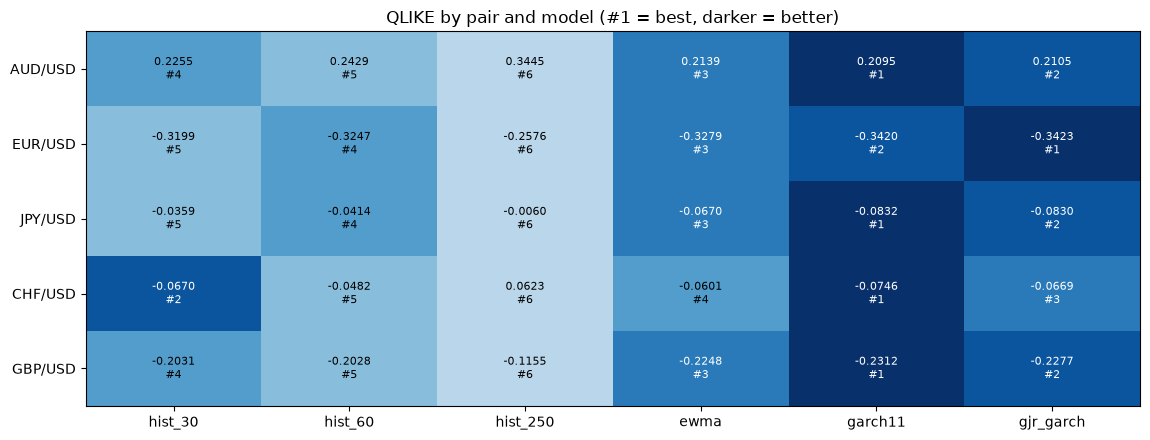

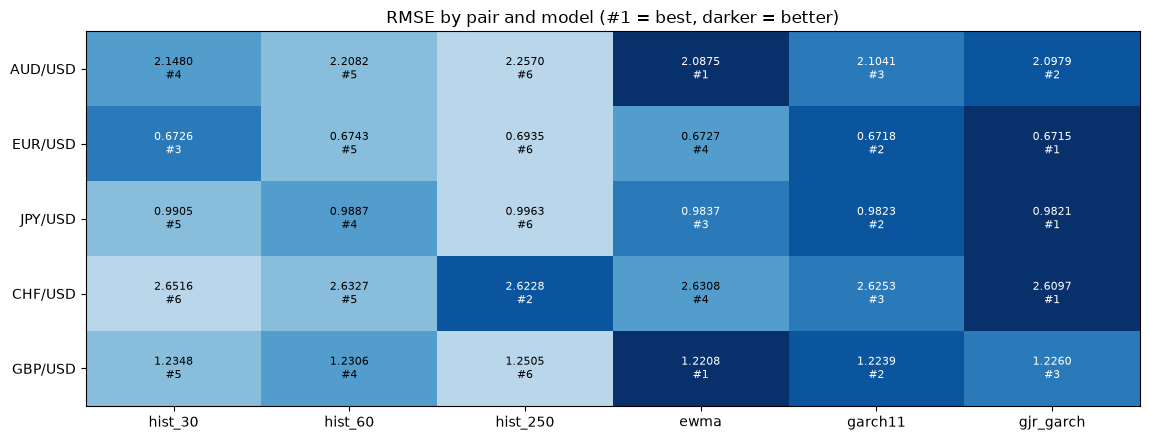

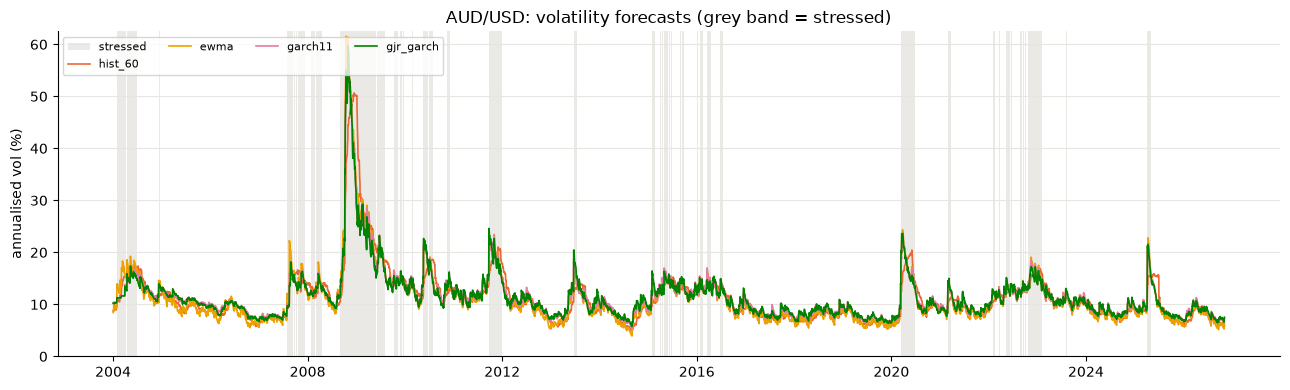

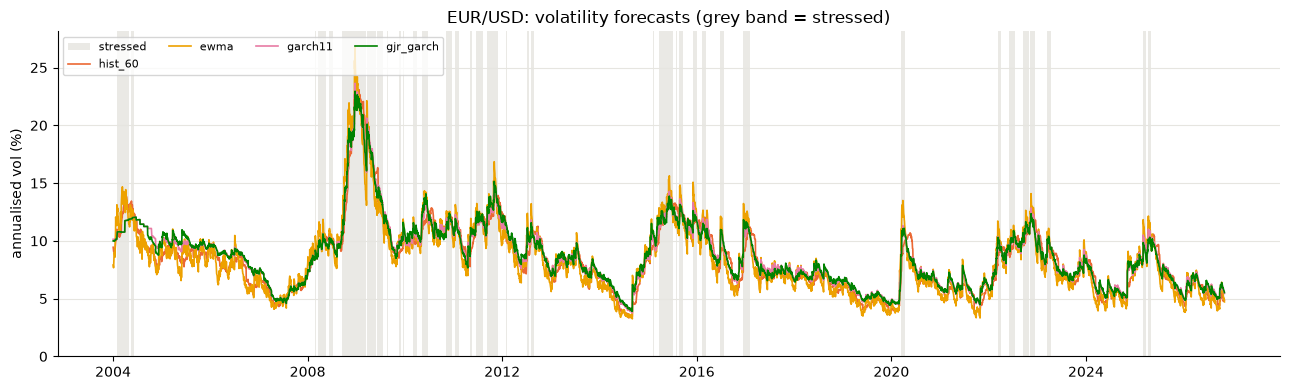

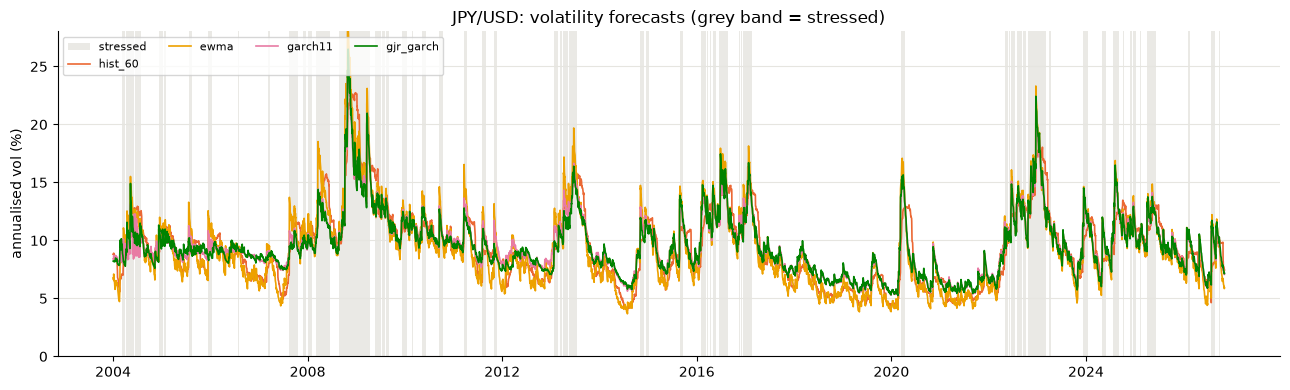

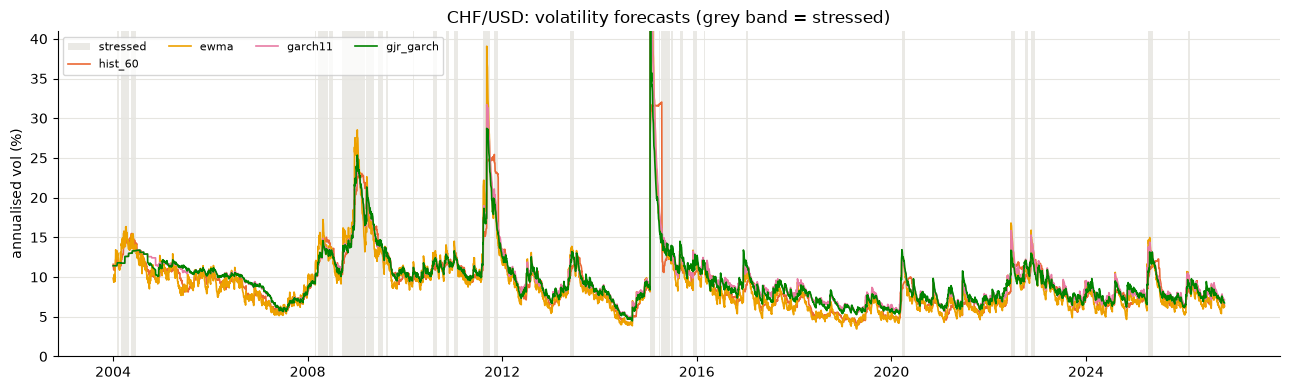

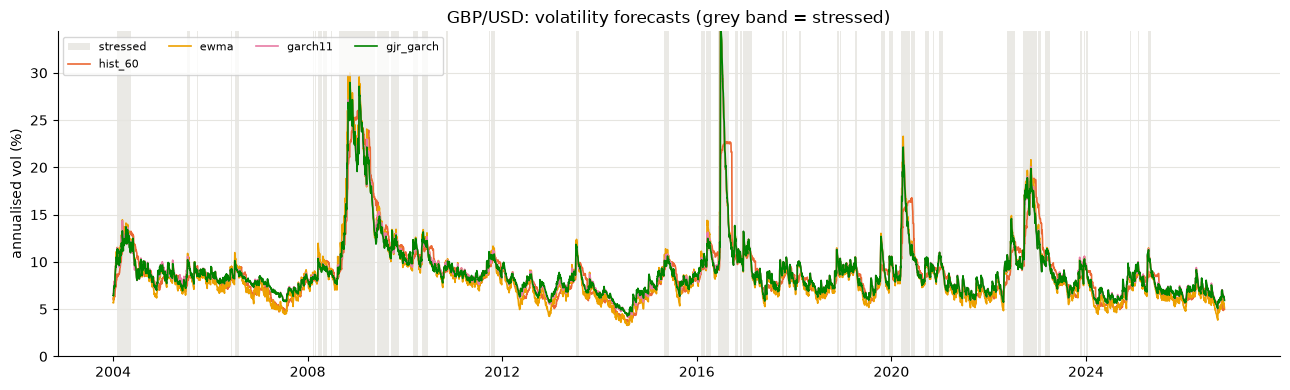

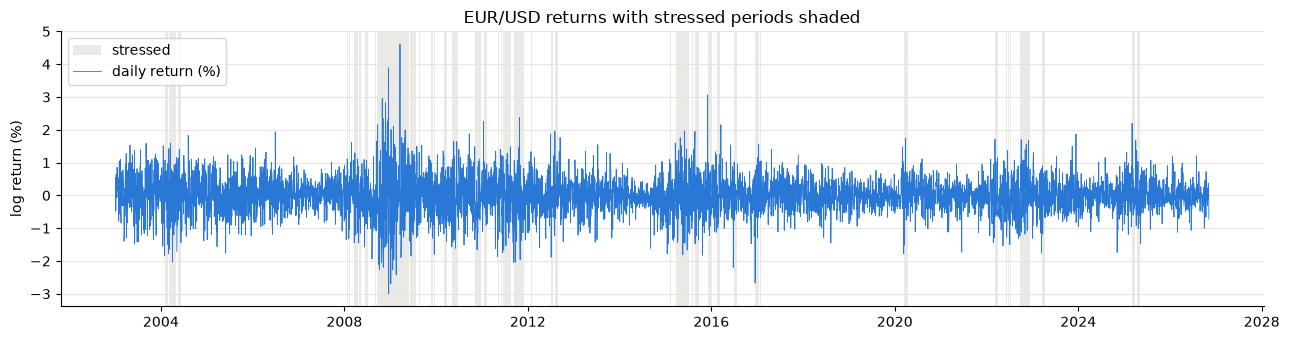

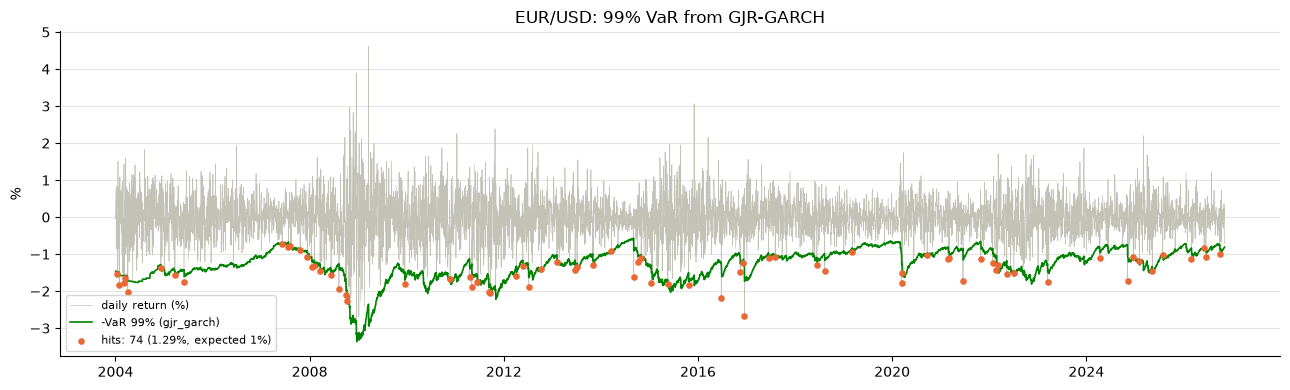

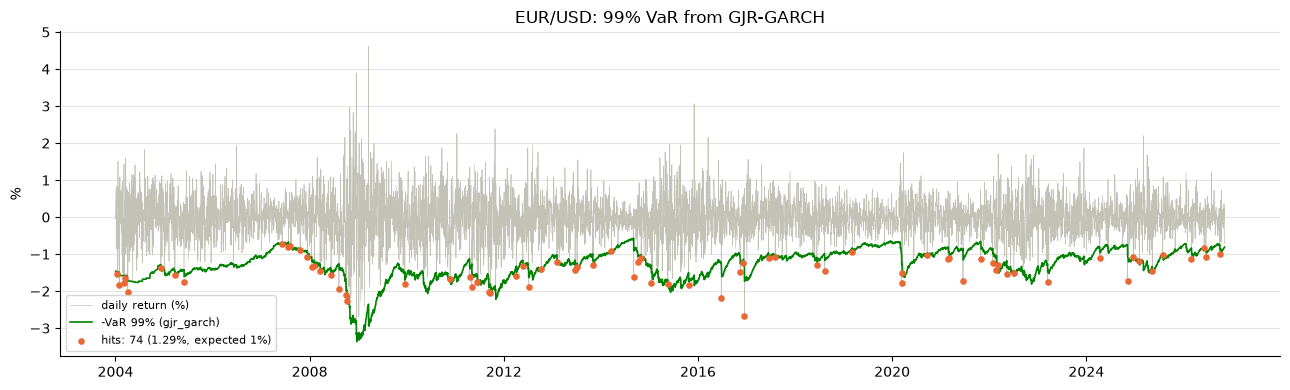

In [11]:
from src.plots import plot_metric_ranks, plot_forecasts, plot_regimes, plot_var_backtest

plot_metric_ranks(run["results"], "QLIKE")
plot_metric_ranks(run["results"], "RMSE")

for c in returns.columns:
  plot_forecasts(run["outs"][c], f"{c}/USD: volatility forecasts (grey band = stressed)",
                 models=["hist_60", "ewma", "garch11", "gjr_garch"], regime=regimes[c])

plot_regimes(returns["EUR"], regimes["EUR"], "EUR/USD returns with stressed periods shaded")
plot_var_backtest(run["outs"]["EUR"], "gjr_garch", 0.01, "EUR/USD: 99% VaR from GJR-GARCH")